In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression, RidgeCV, lasso_path, LogisticRegression
from sklearn.model_selection import KFold, cross_val_score, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, log_loss

# Part 1

- a) There is missing data when attempting to fit model1_sk which raises a ValueError
- b) The model isn't a very good predictor with the $R^2$ being 0.087 between actual and predicted cholesterol
- c) Deleting 80% of the sysBP values is missing completely at random. Using a controlled random state deletion of the data means that the missingness is independent from both observed and unobserved data. 
- d) The model built on the missing sysBP data was much less confident in its coefficients as shown by the wider 95 percent CI's.
- e) In a real worl scenario with missing data, you won't get to calculate the mean from the full dataset since that data is missing, hence why we calculate the mean from the sample that is present.

# Part 2

In [2]:
auto = pd.read_csv("../../data/Auto.csv", na_values="?").dropna().reset_index(drop=True)
 
num = ["displacement", "horsepower", "weight", "acceleration", "year"]
X = auto[num]
y = auto["mpg"]
 
# Same 5-fold CV object for all methods, so the results are comparable
SEED = 200
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
 
# Grid of penalty strengths (sklearn's alpha = glmnet's lambda)
alphas = np.logspace(-3, 3, 100)
auto.shape

(392, 9)

### Q1) 

In [3]:
ols_full = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
sub = ["horsepower", "weight", "year"]
ols_sub = make_pipeline(StandardScaler(), LinearRegression()).fit(X[sub], y)
 
coef_table = pd.DataFrame(index=num)
coef_table["OLS_full"] = ols_full[-1].coef_
coef_table["OLS_hp_wt_yr"] = pd.Series(ols_sub[-1].coef_, index=sub) 
coef_table.loc["intercept"] = [ols_full[-1].intercept_, ols_sub[-1].intercept_]
coef_table

,OLS_full,OLS_hp_wt_yr
displacement,0.290715,NaN
horsepower,0.039216,-0.192201
weight,-5.831154,-5.469742
acceleration,0.248872,NaN
year,2.774417,2.754512
intercept,23.445918,23.445918


- b) Ridge and lasso need standardization so they can assign the penalties evenly regardless of what units the data was measured in. 

### Q2) 

In [4]:
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=cv)).fit(X, y)
print("Ridge alpha_:", ridge[-1].alpha_)
coef_table["Ridge"] = list(ridge[-1].coef_) + [ridge[-1].intercept_]
 
print("Any exactly zero?", np.any(ridge[-1].coef_ == 0))
print("Ridge - OLS_full change:")
print((coef_table.loc[num, "Ridge"] - coef_table.loc[num, "OLS_full"]).round(4))
coef_table

Ridge alpha_: 1.232846739442066
Any exactly zero? False
Ridge - OLS_full change:
displacement   -0.1435
horsepower     -0.0836
weight          0.1972
acceleration   -0.0477
year           -0.0217
dtype: float64


,OLS_full,OLS_hp_wt_yr,Ridge
displacement,0.290715,NaN,0.147261
horsepower,0.039216,-0.192201,-0.044351
weight,-5.831154,-5.469742,-5.633951
acceleration,0.248872,NaN,0.201135
year,2.774417,2.754512,2.752727
intercept,23.445918,23.445918,23.445918


- c) None of the coefficients went all of the way to zero. Although displacement's coefficient changed the most getting almost halved, I do want to point out that Ridge caused the horsepower coefficient to both gain magnitude and flip its sign which I find very odd. 

### Q3) 

In [5]:
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=cv, max_iter=100000)).fit(X, y)
print("Lasso alpha_:", lasso[-1].alpha_)
coef_table["Lasso"] = list(lasso[-1].coef_) + [lasso[-1].intercept_]
 
print("Dropped by lasso:", [f for f, c in zip(num, lasso[-1].coef_) if c == 0])
coef_table

Lasso alpha_: 0.049770235643321115
Dropped by lasso: ['displacement', 'horsepower']


,OLS_full,OLS_hp_wt_yr,Ridge,Lasso
displacement,0.290715,NaN,0.147261,-0.000000
horsepower,0.039216,-0.192201,-0.044351,-0.000000
weight,-5.831154,-5.469742,-5.633951,-5.532356
acceleration,0.248872,NaN,0.201135,0.154151
year,2.774417,2.754512,2.752727,2.720660
intercept,23.445918,23.445918,23.445918,23.445918


- c) Lasso tests all of the coefficients at the same time with a loss function whereas selection will depend on previous decisions on what to add/drop. Lasso also requires normalized data so it should choose features based on their importance instead of selection which can be influenced by the scale of the features. Where lasso may struggle is that collinearity can make the selections unstable whereas selection tends to leave out correlated predictors. 

### Q4)

In [6]:
enet = make_pipeline(
    StandardScaler(),
    ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.5, 0.9, 1], cv=cv, max_iter=100000),
).fit(X, y)
print("ElasticNet alpha_:", enet[-1].alpha_)
print("ElasticNet l1_ratio_:", enet[-1].l1_ratio_)
coef_table["ElasticNet"] = list(enet[-1].coef_) + [enet[-1].intercept_]
display(coef_table.round(4))
 
# Which features does each method keep? (nonzero = True)
display((coef_table.loc[num].fillna(0).abs() > 1e-8))

ElasticNet alpha_: 0.049770235643321115
ElasticNet l1_ratio_: 1.0


,OLS_full,OLS_hp_wt_yr,Ridge,Lasso,ElasticNet
displacement,0.2907,NaN,0.1473,-0.0000,-0.0000
horsepower,0.0392,-0.1922,-0.0444,-0.0000,-0.0000
weight,-5.8312,-5.4697,-5.6340,-5.5324,-5.5324
acceleration,0.2489,NaN,0.2011,0.1542,0.1542
year,2.7744,2.7545,2.7527,2.7207,2.7207
intercept,23.4459,23.4459,23.4459,23.4459,23.4459


,OLS_full,OLS_hp_wt_yr,Ridge,Lasso,ElasticNet
displacement,True,False,True,False,False
horsepower,True,True,True,False,False
weight,True,True,True,True,True
acceleration,True,False,True,True,True
year,True,True,True,True,True


- b) The chosen l1 ratio tells us the mix of lasso compared to ridge, which in this case the elastic net chose 1 so it's the same as the lasso regression we just did.
- c) The weight and year coefficients are hardly touched by the ridge/lasso/elastic net methods compared to the full OLS model so I would say they're the best predictors of mpg out of the 5 variables.

# Part 3

In [7]:
fram = pd.read_csv("../../data/framingham.csv").dropna()
y = fram["TenYearCHD"]
 
# Same CV object as in class
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### Q1)

In [8]:
p_chd = y.mean()
print(f"a) Fraction with CHD: {p_chd:.4f}")
 
baseline_acc = 1 - p_chd  # predict "no CHD" for everyone
print(f"b) Accuracy of always predicting no CHD: {baseline_acc:.4f}")
 
baseline_ll = log_loss(y, np.full(len(y), p_chd))
print(f"c) Log loss with constant p = {p_chd:.4f}: {baseline_ll:.4f}")

a) Fraction with CHD: 0.1523
b) Accuracy of always predicting no CHD: 0.8477
c) Log loss with constant p = 0.1523: 0.4266


### Q2) 

In [9]:
# Model A: numeric = ["age"]
numeric = ["age"]
preprocess = ColumnTransformer(transformers=[
    ("binary", "passthrough", ["male"]),
    ("numeric", StandardScaler(), numeric),
])
model_A = Pipeline([("prep", preprocess), ("logreg", LogisticRegression())])
 
# Model B: numeric = ["cigsPerDay"]
numeric = ["cigsPerDay"]
preprocess = ColumnTransformer(transformers=[
    ("binary", "passthrough", ["male"]),
    ("numeric", StandardScaler(), numeric),
])
model_B = Pipeline([("prep", preprocess), ("logreg", LogisticRegression())])

features = {"A": ["male", "age"], "B": ["male", "cigsPerDay"]}
models = {"A": model_A, "B": model_B}
y_arr = y.to_numpy()
 
probs = {}
for name, model in models.items():
    model.fit(fram[features[name]], y)
    probs[name] = model.predict_proba(fram[features[name]])[:, 1]
    print(f"Model {name} in-sample log loss (sklearn): {log_loss(y, probs[name]):.4f}")

p = probs["A"]
by_hand = -np.mean(y_arr * np.log(p) + (1 - y_arr) * np.log(1 - p))
print(f"Model A log loss (by hand): {by_hand:.4f}")

Model A in-sample log loss (sklearn): 0.3942
Model B in-sample log loss (sklearn): 0.4222
Model A log loss (by hand): 0.3942


### Q3) 

In [10]:
scoring = ["accuracy", "neg_log_loss", "roc_auc"]
rows = []
for name, model in models.items():
    res = cross_validate(model, fram[features[name]], y, cv=cv, scoring=scoring)
    acc, ll, auc = res["test_accuracy"], -res["test_neg_log_loss"], res["test_roc_auc"]
    rows.append({"model": name,
                 "accuracy_mean": acc.mean(), "accuracy_std": acc.std(),
                 "log_loss_mean": ll.mean(), "log_loss_std": ll.std(),
                 "roc_auc_mean": auc.mean(), "roc_auc_std": auc.std()})
cv_results = pd.DataFrame(rows).set_index("model")
display(cv_results.round(4))

,accuracy_mean,accuracy_std,log_loss_mean,log_loss_std,roc_auc_mean,roc_auc_std
model,,,,,,
A,0.8480,0.0010,0.3953,0.0134,0.7013,0.0396
B,0.8477,0.0006,0.4233,0.0023,0.5645,0.0319


- b) The mean accuracy for both models is essentially the baseline accuracy with model A's mean being 0.003 better than the baseline and B being the exact same at 0.8477. Doesn't seem like accuracy is a useful metric for model selection here since they're practiaclly the same value. 

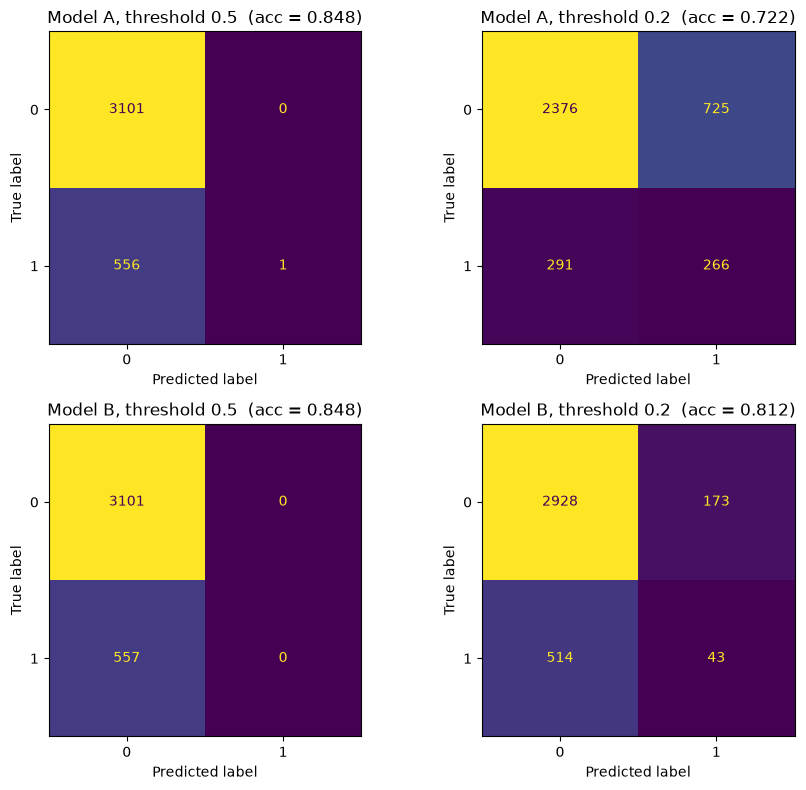

In [11]:
oof = {name: cross_val_predict(model, fram[features[name]], y, cv=cv, method="predict_proba")[:, 1]
       for name, model in models.items()}
 
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for i, name in enumerate(["A", "B"]):
    for j, thr in enumerate([0.5, 0.2]):
        pred = (oof[name] >= thr).astype(int)
        ConfusionMatrixDisplay.from_predictions(y, pred, ax=axes[i, j], colorbar=False)
        axes[i, j].set_title(f"Model {name}, threshold {thr}  (acc = {accuracy_score(y, pred):.3f})")
plt.tight_layout()

- c) When the threshold is 0.5 there's only 1 CHD positive prediction. This is telling me that the threshold is too high and there's almost no predictive power there. Lowering the threshold did make the accuracy go down but it does reduce the number of false negative predictions.
- d) I've been weighing on this for a while and I've settled on model A with the 0.2 threshold being teh best model. In a medical context type 2 errors can be very costly, which is most of the reason why I chose A over B. The other reason is that since I discounted accuracy as a valid tool to compare the models in 3b, the area under the ROC curve is a better tool which model A performs much better at than model B.